# BANKLEDGER
## Banking Transactions and Suspicious Activity Detection

**Project Type:** Data Science | Python | MySQL | MongoDB

**Project Description:**

BankLedger is a banking data analytics project designed to generate,
manage, analyze, and monitor banking transactions.

The project uses Python for data generation and analysis,
MySQL for relational database management, and MongoDB
for NoSQL storage, CRUD operations, indexing, and aggregation.

### Technologies Used
- Python
- Pandas and NumPy
- Matplotlib
- MySQL
- MongoDB Atlas
- Jupyter Notebook

**Project Author:** Ketan Balbhadra Sharma

In [1]:

%pip install pandas numpy matplotlib mysql-connector-python pymongo Faker


   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
    ----------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\Ketan Sharma\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mysql.connector
import pymongo
from faker import Faker

print("BankLedger Project Environment Ready!")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("MySQL Connector:", mysql.connector.__version__)
print("MongoDB:", pymongo.version)

fake = Faker()
print("Sample customer:", fake.name())


BankLedger Project Environment Ready!
Pandas: 3.0.5
NumPy: 2.5.1
MySQL Connector: 26.10.0
MongoDB: 4.20.0
Sample customer: Ashley Weber


## 2. Banking Data Generation

In this stage, Python is used to generate simulated banking
data using the Faker, Pandas, and NumPy libraries.

### Datasets Generated
- Customers: 100 records
- Branches: 5 records
- Account Types: 4 records
- Accounts: 120 records
- Transactions: 650 records
- Loans: 60 records
- Transaction Flags: 61 records

### Key Libraries
- Faker: Generates realistic sample banking information.
- Pandas: Creates and manages datasets.
- NumPy: Supports numerical operations and random data generation.

**Note:** All banking records are simulated and do not represent real customers or transactions.

In [3]:

# BANKLEDGER - STEP 1: GENERATE BASIC BANKING DATA

import pandas as pd
import numpy as np
from faker import Faker
from pathlib import Path

# Make results reproducible
np.random.seed(42)
fake = Faker("en_IN")
Faker.seed(42)

# Create a folder to save our datasets
Path("datasets").mkdir(exist_ok=True)

# --------------------------------
# 1. CUSTOMERS DATASET
# --------------------------------

customers = []

for i in range(1, 101):
    customers.append({
        "customer_id": i,
        "first_name": fake.first_name(),
        "last_name": fake.last_name(),
        "email": f"customer{i}@bankledger.com",
        "phone": "9" + str(np.random.randint(100000000, 999999999)),
        "date_of_birth": fake.date_of_birth(
            minimum_age=21, maximum_age=70
        ),
        "address": fake.address().replace("\n", ", ")
    })

customers_df = pd.DataFrame(customers)

# --------------------------------
# 2. BRANCHES DATASET
# --------------------------------

branches_df = pd.DataFrame([
    [1, "Mumbai Main Branch", "Mumbai", "Maharashtra"],
    [2, "Pune City Branch", "Pune", "Maharashtra"],
    [3, "Delhi Central Branch", "Delhi", "Delhi"],
    [4, "Bangalore Branch", "Bangalore", "Karnataka"],
    [5, "Hyderabad Branch", "Hyderabad", "Telangana"]
], columns=[
    "branch_id", "branch_name", "city", "state"
])

# --------------------------------
# 3. ACCOUNT TYPES DATASET
# --------------------------------

account_types_df = pd.DataFrame([
    [1, "Savings", "Personal savings account"],
    [2, "Current", "Business current account"],
    [3, "Salary", "Employee salary account"],
    [4, "Fixed Deposit", "Fixed deposit account"]
], columns=[
    "account_type_id", "type_name", "description"
])

# --------------------------------
# 4. ACCOUNTS DATASET
# --------------------------------

accounts = []

for i in range(1, 121):
    accounts.append({
        "account_id": i,
        "customer_id": np.random.randint(1, 101),
        "branch_id": np.random.randint(1, 6),
        "account_type_id": np.random.randint(1, 5),
        "account_number": f"BL2026{i:06d}",
        "opening_date": fake.date_between(
            start_date="-5y", end_date="today"
        ),
        "balance": round(
            np.random.uniform(5000, 200000), 2
        ),
        "status": np.random.choice(
            ["ACTIVE", "DORMANT", "CLOSED"],
            p=[0.75, 0.20, 0.05]
        )
    })

accounts_df = pd.DataFrame(accounts)

# --------------------------------
# 5. SAVE DATASETS AS CSV FILES
# --------------------------------

customers_df.to_csv("datasets/customers.csv", index=False)
branches_df.to_csv("datasets/branches.csv", index=False)
account_types_df.to_csv("datasets/account_types.csv", index=False)
accounts_df.to_csv("datasets/accounts.csv", index=False)

# --------------------------------
# 6. DISPLAY RESULTS
# --------------------------------

print("BANKLEDGER BASIC DATASETS CREATED SUCCESSFULLY!")

print("\nCUSTOMERS:", customers_df.shape)
print("BRANCHES:", branches_df.shape)
print("ACCOUNT TYPES:", account_types_df.shape)
print("ACCOUNTS:", accounts_df.shape)

print("\nCUSTOMER DATA PREVIEW:")
display(customers_df.head())

print("\nACCOUNT DATA PREVIEW:")
display(accounts_df.head())


BANKLEDGER BASIC DATASETS CREATED SUCCESSFULLY!

CUSTOMERS: (100, 7)
BRANCHES: (5, 4)
ACCOUNT TYPES: (4, 3)
ACCOUNTS: (120, 8)

CUSTOMER DATA PREVIEW:


,customer_id,first_name,last_name,email,phone,date_of_birth,address
0,1,Isaac,Bakshi,customer1@bankledger.com,9634895718,1974-08-01,"181, Sami, Ludhiana-338908"
1,2,Rushil,Saini,customer2@bankledger.com,9299900595,1970-11-14,"H.No. 265, Dugal Road, Naihati-161559"
2,3,Aishani,Bassi,customer3@bankledger.com,9962061404,2005-07-11,"18, Pathak Road, Coimbatore-341316"
3,4,Arunima,Setty,customer4@bankledger.com,9887846414,1999-02-16,"H.No. 53, Bora Road, Deoghar 276483"
4,5,Ekta,Bhalla,customer5@bankledger.com,9227521863,1971-06-16,"41, Murty Ganj, Panchkula 724238"



ACCOUNT DATA PREVIEW:


,account_id,customer_id,branch_id,account_type_id,account_number,opening_date,balance,status
0,1,62,5,4,BL2026000001,2026-03-08,150727.42,ACTIVE
1,2,24,2,1,BL2026000002,2026-03-15,59782.23,ACTIVE
2,3,41,5,3,BL2026000003,2026-05-24,37227.05,ACTIVE
3,4,9,1,4,BL2026000004,2026-01-12,62230.19,ACTIVE
4,5,81,3,3,BL2026000005,2026-08-27,155397.72,ACTIVE


In [4]:

# BANKLEDGER - DATASET INSPECTION

import pandas as pd

print("BANKLEDGER DATASET INSPECTION")
print("=" * 50)

for name, data in list(globals().items()):
    if isinstance(data, pd.DataFrame):
        print(f"\nDataset: {name}")
        print("Shape:", data.shape)
        print("Columns:", list(data.columns))
        print("-" * 50)


BANKLEDGER DATASET INSPECTION

Dataset: customers_df
Shape: (100, 7)
Columns: ['customer_id', 'first_name', 'last_name', 'email', 'phone', 'date_of_birth', 'address']
--------------------------------------------------

Dataset: branches_df
Shape: (5, 4)
Columns: ['branch_id', 'branch_name', 'city', 'state']
--------------------------------------------------

Dataset: account_types_df
Shape: (4, 3)
Columns: ['account_type_id', 'type_name', 'description']
--------------------------------------------------

Dataset: accounts_df
Shape: (120, 8)
Columns: ['account_id', 'customer_id', 'branch_id', 'account_type_id', 'account_number', 'opening_date', 'balance', 'status']
--------------------------------------------------


## 3. Transaction, Loan and Suspicious Activity Data Generation

This stage generates additional banking records using Python,
NumPy, Pandas, and Faker.

### Datasets Created
- Transactions: 650 records
- Loans: 60 records
- Transaction Flags: 61 records

### Transaction Categories
- DEPOSIT
- WITHDRAWAL

### Suspicious Activity Monitoring

Transactions involving high-value deposits above ₹80,000
are flagged for review.

**Note:** These are simulated alerts for analytical purposes,
not confirmed cases of financial fraud.

In [5]:

# BANKLEDGER - STEP 2: TRANSACTIONS, LOANS AND FLAGS

import pandas as pd
import numpy as np
from faker import Faker

np.random.seed(42)
fake = Faker("en_IN")
Faker.seed(42)

# ------------------------------------------
# 1. PREPARE ACCOUNT BALANCES
# ------------------------------------------

running_balances = accounts_df.set_index(
    "account_id"
)["balance"].astype(float).to_dict()

account_ids = accounts_df["account_id"].tolist()

transactions = []
transaction_flags = []

# ------------------------------------------
# 2. GENERATE 650 TRANSACTIONS
# ------------------------------------------

for i in range(1, 651):

    account_id = int(np.random.choice(account_ids))
    current_balance = running_balances[account_id]

    # First 61 transactions are deliberately
    # high-value deposits for suspicious activity analysis.

    if i <= 61:
        transaction_type = "DEPOSIT"
        amount = round(float(np.random.uniform(80000, 150000)), 2)

    else:
        transaction_type = np.random.choice(
            ["DEPOSIT", "WITHDRAWAL"],
            p=[0.55, 0.45]
        )

        if transaction_type == "DEPOSIT":
            amount = round(float(np.random.uniform(500, 25000)), 2)

        else:
            # Never withdraw more than the available balance.
            max_withdrawal = min(current_balance, 25000)

            if max_withdrawal < 500:
                transaction_type = "DEPOSIT"
                amount = round(float(np.random.uniform(500, 25000)), 2)
            else:
                amount = round(
                    float(np.random.uniform(500, max_withdrawal)), 2
                )

    # Simulate balance changes before importing into MySQL.
    if transaction_type == "DEPOSIT":
        running_balances[account_id] += amount
    else:
        running_balances[account_id] -= amount

    transaction_date = fake.date_time_between(
        start_date="-1y",
        end_date="now"
    )

    transactions.append({
        "transaction_id": i,
        "account_id": account_id,
        "transaction_type": transaction_type,
        "amount": amount,
        "transaction_date": transaction_date,
        "description": (
            "High-value deposit"
            if i <= 61
            else f"{transaction_type.title()} transaction"
        ),
        "reference_no": f"BLTXN{i:06d}",
        "transfer_group_id": None
    })

    # Create a flag for each high-value deposit.
    if i <= 61:
        transaction_flags.append({
            "transaction_id": i,
            "flag_type": "HIGH_VALUE_TRANSACTION",
            "severity": "HIGH",
            "flag_reason": (
                "Deposit exceeds the project high-value "
                "monitoring threshold of INR 80000"
            ),
            "status": "OPEN"
        })

transactions_df = pd.DataFrame(transactions)
transaction_flags_df = pd.DataFrame(transaction_flags)

# ------------------------------------------
# 3. GENERATE 60 LOANS
# ------------------------------------------

loan_types = [
    "Personal Loan",
    "Home Loan",
    "Education Loan",
    "Vehicle Loan",
    "Business Loan"
]

loans = []

for i in range(1, 61):

    start_date = fake.date_between(
        start_date="-4y",
        end_date="today"
    )

    loan_duration = int(np.random.choice([1, 2, 3, 5, 10, 15, 20]))

    end_date = start_date + pd.DateOffset(years=loan_duration)

    loans.append({
        "customer_id": int(np.random.randint(1, 101)),
        "branch_id": int(np.random.randint(1, 6)),
        "loan_type": str(np.random.choice(loan_types)),
        "principal_amount": round(
            float(np.random.uniform(50000, 1500000)), 2
        ),
        "interest_rate": round(
            float(np.random.uniform(7, 15)), 2
        ),
        "start_date": start_date,
        "end_date": end_date,
        "loan_status": str(
            np.random.choice(
                ["ACTIVE", "CLOSED", "PENDING"],
                p=[0.70, 0.20, 0.10]
            )
        )
    })

loans_df = pd.DataFrame(loans)

# ------------------------------------------
# 4. SAVE ALL THREE DATASETS
# ------------------------------------------

transactions_df.to_csv(
    "datasets/transactions.csv", index=False
)

loans_df.to_csv(
    "datasets/loans.csv", index=False
)

transaction_flags_df.to_csv(
    "datasets/transaction_flags.csv", index=False
)

# ------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------

print("BANKLEDGER REMAINING DATASETS CREATED!")
print("=" * 45)

print("Transactions:", transactions_df.shape)
print("Loans:", loans_df.shape)
print("Transaction Flags:", transaction_flags_df.shape)

print("\nTOTAL PLANNED RECORDS:")
total = (
    len(customers_df)
    + len(branches_df)
    + len(account_types_df)
    + len(accounts_df)
    + len(transactions_df)
    + len(loans_df)
    + len(transaction_flags_df)
)

print(total)

print("\nTRANSACTION TYPE SUMMARY:")
print(transactions_df["transaction_type"].value_counts())

print("\nTRANSACTION PREVIEW:")
display(transactions_df.head())

print("\nLOAN PREVIEW:")
display(loans_df.head())

print("\nSUSPICIOUS FLAGS PREVIEW:")
display(transaction_flags_df.head())


BANKLEDGER REMAINING DATASETS CREATED!
Transactions: (650, 8)
Loans: (60, 8)
Transaction Flags: (61, 5)

TOTAL PLANNED RECORDS:
1000

TRANSACTION TYPE SUMMARY:
transaction_type
DEPOSIT       408
WITHDRAWAL    242
Name: count, dtype: int64

TRANSACTION PREVIEW:


,transaction_id,account_id,transaction_type,amount,transaction_date,description,reference_no,transfer_group_id
0,1,103,DEPOSIT,135758.01,2026-07-20 18:38:23,High-value deposit,BLTXN000001,None
1,2,15,DEPOSIT,131239.58,2025-12-27 16:25:50,High-value deposit,BLTXN000002,None
2,3,61,DEPOSIT,121779.51,2025-11-24 03:52:01,High-value deposit,BLTXN000003,None
3,4,83,DEPOSIT,86998.24,2026-08-29 10:30:05,High-value deposit,BLTXN000004,None
4,5,75,DEPOSIT,140632.33,2026-03-01 06:12:32,High-value deposit,BLTXN000005,None



LOAN PREVIEW:


,customer_id,branch_id,loan_type,principal_amount,interest_rate,start_date,end_date,loan_status
0,18,3,Home Loan,670889.44,12.74,2024-07-24,2034-07-24,ACTIVE
1,24,4,Education Loan,924668.14,9.70,2024-04-06,2044-04-06,PENDING
2,36,5,Personal Loan,913838.56,10.21,2024-01-20,2034-01-20,ACTIVE
3,41,4,Business Loan,802636.70,7.54,2026-07-18,2041-07-18,CLOSED
4,32,5,Home Loan,1036191.30,8.85,2023-03-01,2026-03-01,ACTIVE



SUSPICIOUS FLAGS PREVIEW:


,transaction_id,flag_type,severity,flag_reason,status
0,1,HIGH_VALUE_TRANSACTION,HIGH,Deposit exceeds the project high-value monitor...,OPEN
1,2,HIGH_VALUE_TRANSACTION,HIGH,Deposit exceeds the project high-value monitor...,OPEN
2,3,HIGH_VALUE_TRANSACTION,HIGH,Deposit exceeds the project high-value monitor...,OPEN
3,4,HIGH_VALUE_TRANSACTION,HIGH,Deposit exceeds the project high-value monitor...,OPEN
4,5,HIGH_VALUE_TRANSACTION,HIGH,Deposit exceeds the project high-value monitor...,OPEN


## 4. MySQL Database Connection and Data Import

MySQL is used as the relational database management system
for the BankLedger project.

### Database Operations

1. Establish a connection between Python and MySQL.
2. Prepare and clean the generated datasets.
3. Import records into the appropriate database tables.
4. Maintain relationships using primary and foreign keys.
5. Verify the imported records.

### Database Tables

- Customers
- Branches
- Account Types
- Accounts
- Transactions
- Loans
- Transaction Flags
- Balance Audit

**Database:** BankLedger  
**Total Records:** 1,650 across 8 tables.

In [42]:
import mysql.connector
from getpass import getpass

mysql_password = getpass("Enter MySQL password: ")

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password=mysql_password,
    database="BankLedger"
)

if connection.is_connected():
    print("Successfully connected to BankLedger database!")

Enter MySQL password:  ········


Successfully connected to BankLedger database!


In [43]:
cursor = connection.cursor()

cursor.execute("SHOW TABLES")

for table in cursor.fetchall():
    print(table[0])

account_types
accounts
balance_audit
branches
customer_account_summary
customers
loans
transaction_flags
transactions


In [44]:
tables = [
    "customers",
    "branches",
    "account_types",
    "accounts",
    "transactions",
    "loans",
    "transaction_flags",
    "balance_audit"
]

for table in tables:
    cursor.execute(f"SELECT COUNT(*) FROM `{table}`")
    count = cursor.fetchone()[0]
    print(f"{table}: {count} records")

customers: 100 records
branches: 5 records
account_types: 4 records
accounts: 120 records
transactions: 650 records
loans: 60 records
transaction_flags: 61 records
balance_audit: 650 records


In [45]:

import pandas as pd

# 1. Read all seven CSV files
customers = pd.read_csv("datasets/customers.csv")
branches = pd.read_csv("datasets/branches.csv")
account_types = pd.read_csv("datasets/account_types.csv")
accounts = pd.read_csv("datasets/accounts.csv")
loans = pd.read_csv("datasets/loans.csv")
transactions = pd.read_csv("datasets/transactions.csv")
flags = pd.read_csv("datasets/transaction_flags.csv")

# 2. Convert date columns
customers["date_of_birth"] = pd.to_datetime(
    customers["date_of_birth"]
).dt.date

accounts["opening_date"] = pd.to_datetime(
    accounts["opening_date"]
).dt.date

loans["start_date"] = pd.to_datetime(
    loans["start_date"]
).dt.date

loans["end_date"] = pd.to_datetime(
    loans["end_date"]
).dt.date

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)

# 3. Prepare all records safely
def prepare_records(df):
    clean_df = df.astype(object)

    clean_df = clean_df.where(pd.notna(clean_df), None)

    records = [
        tuple(None if pd.isna(value) else value for value in row)
        for row in clean_df.itertuples(index=False, name=None)
    ]

    return records

# 4. Prepare insertion statements
insert_statements = [
    ("customers",
     """INSERT INTO customers
     (customer_id, first_name, last_name, email, phone,
      date_of_birth, address)
     VALUES (%s,%s,%s,%s,%s,%s,%s)""", customers),

    ("branches",
     """INSERT INTO branches
     (branch_id, branch_name, city, state)
     VALUES (%s,%s,%s,%s)""", branches),

    ("account_types",
     """INSERT INTO account_types
     (account_type_id, type_name, description)
     VALUES (%s,%s,%s)""", account_types),

    ("accounts",
     """INSERT INTO accounts
     (account_id, customer_id, branch_id, account_type_id,
      account_number, opening_date, balance, status)
     VALUES (%s,%s,%s,%s,%s,%s,%s,%s)""", accounts),

    ("loans",
     """INSERT INTO loans
     (customer_id, branch_id, loan_type, principal_amount,
      interest_rate, start_date, end_date, loan_status)
     VALUES (%s,%s,%s,%s,%s,%s,%s,%s)""", loans),

    ("transactions",
     """INSERT INTO transactions
     (transaction_id, account_id, transaction_type, amount,
      transaction_date, description, reference_no, transfer_group_id)
     VALUES (%s,%s,%s,%s,%s,%s,%s,%s)""", transactions),

    ("transaction_flags",
     """INSERT INTO transaction_flags
     (transaction_id, flag_type, severity, flag_reason, status)
     VALUES (%s,%s,%s,%s,%s)""", flags)
]

# 5. Check that all destination tables are empty
try:
    for table_name, sql, df in insert_statements:
        cursor.execute(f"SELECT COUNT(*) FROM `{table_name}`")
        existing = cursor.fetchone()[0]

        if existing != 0:
            raise Exception(
                f"{table_name} already contains {existing} records. "
                "Import stopped to prevent duplicates."
            )

    # 6. Import everything in one transaction
    for table_name, sql, df in insert_statements:
        records = prepare_records(df)
        cursor.executemany(sql, records)

        print(f"Imported {len(records)} records into {table_name}")

    connection.commit()

    print("\nALL SEVEN DATASETS IMPORTED SUCCESSFULLY!")

except Exception as e:
    connection.rollback()

    print("\nIMPORT FAILED. Changes have been rolled back.")
    print("Error:", e)



IMPORT FAILED. Changes have been rolled back.
Error: customers already contains 100 records. Import stopped to prevent duplicates.


In [46]:
tables = [
    "customers",
    "branches",
    "account_types",
    "accounts",
    "transactions",
    "loans",
    "transaction_flags",
    "balance_audit"
]

total = 0

for table in tables:
    cursor.execute(f"SELECT COUNT(*) FROM `{table}`")
    count = cursor.fetchone()[0]

    print(f"{table}: {count} records")

    if table != "balance_audit":
        total += count

print("\nTotal planned records:", total)

customers: 100 records
branches: 5 records
account_types: 4 records
accounts: 120 records
transactions: 650 records
loans: 60 records
transaction_flags: 61 records
balance_audit: 650 records

Total planned records: 1000


In [47]:
cursor.execute("""
SELECT
    a.account_id,
    a.balance,
    COUNT(t.transaction_id) AS total_transactions
FROM accounts a
LEFT JOIN transactions t
    ON a.account_id = t.account_id
GROUP BY a.account_id, a.balance
ORDER BY a.account_id
LIMIT 10
""")

results = cursor.fetchall()

for row in results:
    print(row)

(1, Decimal('274932.33'), 8)
(2, Decimal('393585.79'), 10)
(3, Decimal('164811.48'), 10)
(4, Decimal('157349.09'), 3)
(5, Decimal('483026.98'), 11)
(6, Decimal('263937.27'), 9)
(7, Decimal('90928.51'), 3)
(8, Decimal('6754.96'), 9)
(9, Decimal('133624.42'), 6)
(10, Decimal('100993.53'), 5)


## 5. Python Data Analysis and Visualizations

Pandas and NumPy are used to analyze banking transaction
records retrieved from the MySQL database.

### Analysis Performed

1. Retrieve transaction records from MySQL.
2. Convert transaction dates into datetime format.
3. Analyze daily transaction activity.
4. Analyze hourly transaction patterns.
5. Identify the busiest and quietest transaction hours.
6. Visualize transaction trends using Matplotlib.

### Objective

To understand transaction patterns, identify activity trends,
and present banking data through meaningful visualizations.

In [48]:

import pandas as pd

# Retrieve transactions from MySQL
cursor = connection.cursor()

query = """
SELECT
    transaction_id,
    account_id,
    transaction_type,
    amount,
    transaction_date
FROM transactions
ORDER BY transaction_date;
"""

cursor.execute(query)

records = cursor.fetchall()

columns = [
    "transaction_id",
    "account_id",
    "transaction_type",
    "amount",
    "transaction_date"
]

transactions_df = pd.DataFrame(records, columns=columns)

# Convert transaction_date into datetime format
transactions_df["transaction_date"] = pd.to_datetime(
    transactions_df["transaction_date"]
)

print("DATA RETRIEVED SUCCESSFULLY!")
print("Dataset shape:", transactions_df.shape)

display(transactions_df.head(10))


DATA RETRIEVED SUCCESSFULLY!
Dataset shape: (650, 5)


,transaction_id,account_id,transaction_type,amount,transaction_date
0,236,1,WITHDRAWAL,15351.28,2025-11-14 16:04:49
1,396,37,WITHDRAWAL,20828.67,2025-11-15 06:50:22
2,208,6,WITHDRAWAL,24458.57,2025-11-15 16:59:54
3,549,53,WITHDRAWAL,12705.80,2025-11-15 19:47:53
4,39,80,DEPOSIT,132312.41,2025-11-16 23:19:22
5,301,10,DEPOSIT,13948.59,2025-11-17 05:46:24
6,507,108,DEPOSIT,18416.12,2025-11-17 11:39:59
7,478,92,WITHDRAWAL,21748.71,2025-11-18 01:34:34
8,562,12,DEPOSIT,11912.41,2025-11-18 04:52:41
9,191,35,WITHDRAWAL,9097.42,2025-11-18 21:45:39


,transaction_day,total_transactions
0,2025-11-14,1
1,2025-11-15,3
2,2025-11-16,1
3,2025-11-17,2
4,2025-11-18,3
5,2025-11-20,1
6,2025-11-22,2
7,2025-11-23,1
8,2025-11-24,3
9,2025-11-26,4


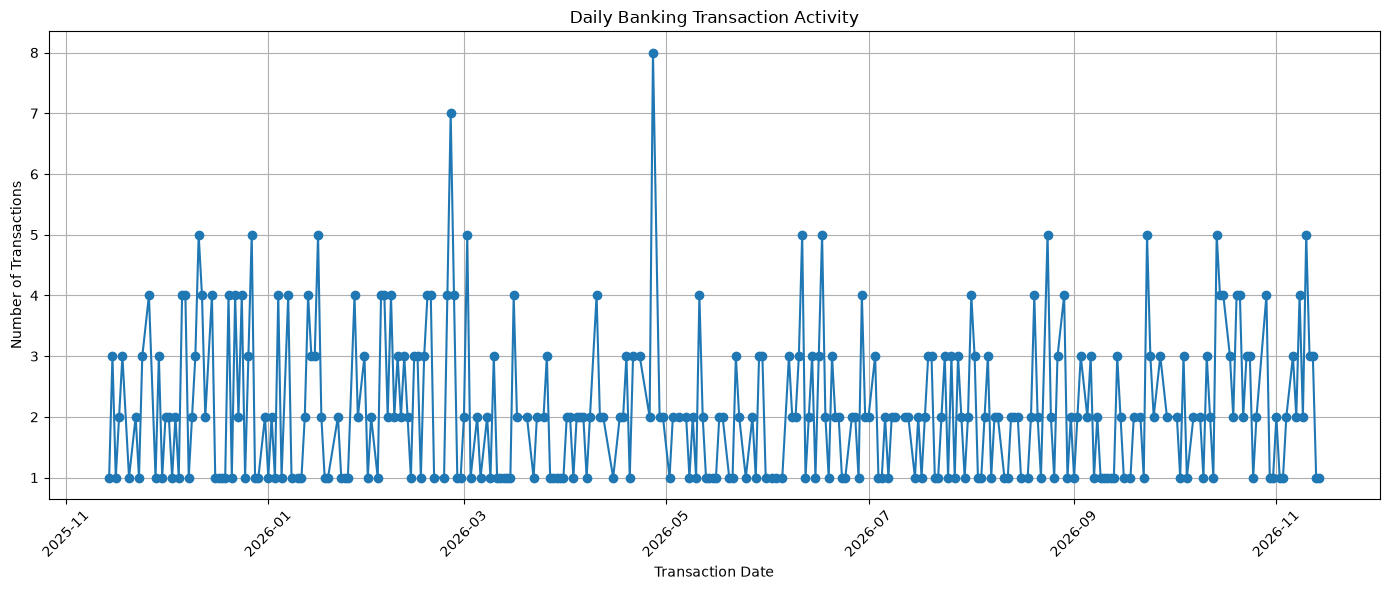

In [49]:

import matplotlib.pyplot as plt

# Extract only the date from transaction_date
transactions_df["transaction_day"] = (
    transactions_df["transaction_date"].dt.date
)

# Count transactions for each day
daily_transactions = (
    transactions_df.groupby("transaction_day")
    .size()
    .reset_index(name="total_transactions")
)

# Display daily transaction summary
display(daily_transactions.head(10))

# Create chart
plt.figure(figsize=(14, 6))

plt.plot(
    daily_transactions["transaction_day"],
    daily_transactions["total_transactions"],
    marker="o"
)

plt.title("Daily Banking Transaction Activity")
plt.xlabel("Transaction Date")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()


,transaction_hour,total_transactions
0,0,29
1,1,34
2,2,23
3,3,31
4,4,22
5,5,32
6,6,29
7,7,34
8,8,25
9,9,23


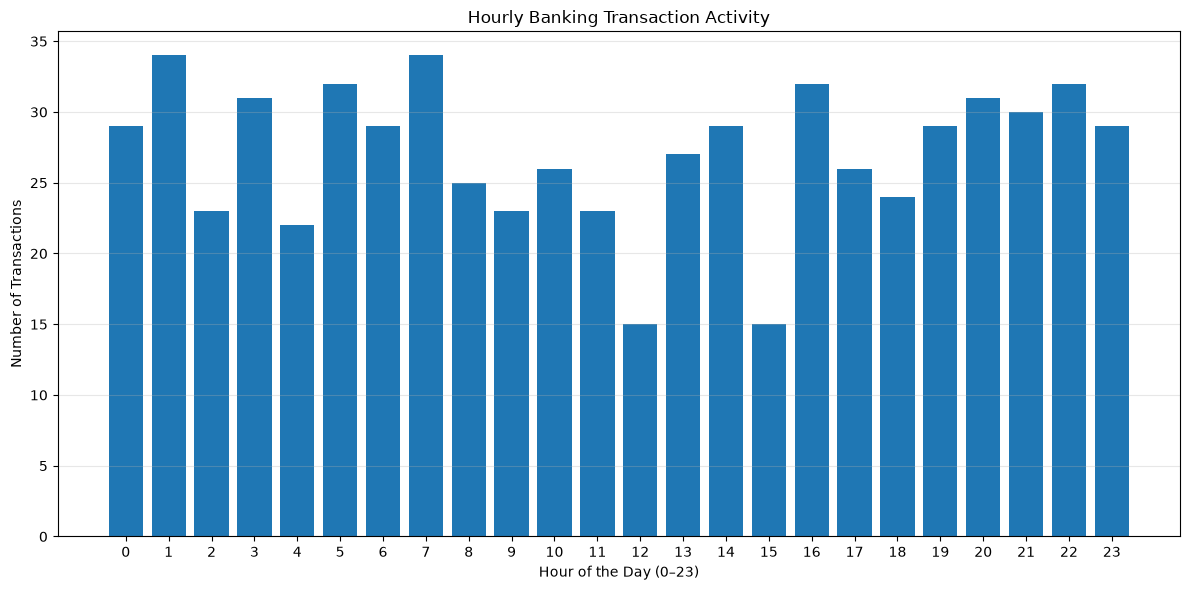

In [50]:

import matplotlib.pyplot as plt

# Extract hour from transaction date and time
transactions_df["transaction_hour"] = (
    transactions_df["transaction_date"].dt.hour
)

# Count transactions for each hour
hourly_transactions = (
    transactions_df.groupby("transaction_hour")
    .size()
    .reindex(range(24), fill_value=0)
    .reset_index(name="total_transactions")
)

# Display hourly transaction summary
display(hourly_transactions)

# Create hourly activity chart
plt.figure(figsize=(12, 6))

plt.bar(
    hourly_transactions["transaction_hour"],
    hourly_transactions["total_transactions"]
)

plt.title("Hourly Banking Transaction Activity")
plt.xlabel("Hour of the Day (0–23)")
plt.ylabel("Number of Transactions")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()


In [51]:

# Find busiest and quietest hours
busiest = hourly_transactions[
    hourly_transactions["total_transactions"]
    == hourly_transactions["total_transactions"].max()
]

quietest = hourly_transactions[
    hourly_transactions["total_transactions"]
    == hourly_transactions["total_transactions"].min()
]

print("BANKLEDGER - HOURLY ANALYSIS")
print("-" * 40)

print("\nBusiest hour(s):")
display(busiest)

print("\nQuietest hour(s):")
display(quietest)

print("\nTotal transactions:", 
      hourly_transactions["total_transactions"].sum())


BANKLEDGER - HOURLY ANALYSIS
----------------------------------------

Busiest hour(s):


,transaction_hour,total_transactions
1,1,34
7,7,34



Quietest hour(s):


,transaction_hour,total_transactions
12,12,15
15,15,15



Total transactions: 650


## 6. MongoDB Atlas Connection and Data Migration

MongoDB Atlas is used as the NoSQL database in the BankLedger project.

### Operations Performed

1. Establish a secure connection with MongoDB Atlas.
2. Create and access the BankLedger database.
3. Create the required collections.
4. Migrate transaction records from MySQL to MongoDB.
5. Store transaction flags in a separate collection.
6. Verify the migrated documents.

### Collections
- transactions: 650 documents
- transaction_flags: 61 documents

### Objective

To demonstrate data migration and the use of a NoSQL database
alongside a relational database.

In [52]:

from pymongo import MongoClient

try:
    client = MongoClient(
        "mongodb://localhost:27017/",
        serverSelectionTimeoutMS=5000
    )

    # Test MongoDB server
    client.admin.command("ping")

    print("MongoDB connected successfully!")
    print("MongoDB server is running.")

except Exception as e:
    print("MongoDB connection failed.")
    print("Error:", e)


MongoDB connection failed.
Error: localhost:27017: [WinError 10061] No connection could be made because the target machine actively refused it (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms), Timeout: 5.0s, Topology Description: <TopologyDescription id: 6af99c5a7876819ddb3aa73b, topology_type: Unknown, servers: [<ServerDescription ('localhost', 27017) server_type: Unknown, rtt: None, error=AutoReconnect('localhost:27017: [WinError 10061] No connection could be made because the target machine actively refused it (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms)')>]>


In [53]:
%pip install "pymongo[srv]"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\Ketan Sharma\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [8]:

from pymongo import MongoClient
from getpass import getpass
from urllib.parse import quote_plus

# MongoDB Atlas credentials
username = "ketansharma1303_db_user"

# Enter the password you just created
password = getpass("Enter your new MongoDB password: ")

# Encode password to handle special characters
encoded_password = quote_plus(password)

# Atlas connection
uri = (
    f"mongodb+srv://{username}:{encoded_password}"
    "@cluster0.ocbuygc.mongodb.net/"
    "?retryWrites=true&w=majority&appName=Cluster0"
)

# Connect
client = MongoClient(uri, serverSelectionTimeoutMS=15000)

# Test connection
client.admin.command("ping")

# Select database
mongo_db = client["BankLedger"]

print("MongoDB Atlas connected successfully!")
print("Database:", mongo_db.name)


Enter your new MongoDB password:  ········


MongoDB Atlas connected successfully!
Database: BankLedger


In [4]:
import sys
import ssl
import pymongo

print("Python version:", sys.version)
print("SSL version:", ssl.OPENSSL_VERSION)
print("PyMongo version:", pymongo.version)

Python version: 3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]
SSL version: OpenSSL 3.0.18 30 Sep 2025
PyMongo version: 4.20.0


In [6]:
import dns.resolver
import socket
import ssl

records = dns.resolver.resolve(
    "_mongodb._tcp.cluster0.ocbuygc.mongodb.net",
    "SRV"
)

for record in records:
    host = str(record.target).rstrip(".")
    port = record.port

    print("Testing:", host, port)

    try:
        with socket.create_connection((host, port), timeout=10) as sock:
            with ssl.create_default_context().wrap_socket(
                sock, server_hostname=host
            ) as secure_sock:
                print("TLS connection successful!")
                print("TLS version:", secure_sock.version())

    except Exception as error:
        print("TLS connection failed:", repr(error))

Testing: ac-dinazcr-shard-00-01.ocbuygc.mongodb.net 27017
TLS connection failed: SSLError(1, '[SSL: TLSV1_ALERT_INTERNAL_ERROR] tlsv1 alert internal error (_ssl.c:1081)')
Testing: ac-dinazcr-shard-00-02.ocbuygc.mongodb.net 27017
TLS connection failed: SSLError(1, '[SSL: TLSV1_ALERT_INTERNAL_ERROR] tlsv1 alert internal error (_ssl.c:1081)')
Testing: ac-dinazcr-shard-00-00.ocbuygc.mongodb.net 27017
TLS connection failed: SSLError(1, '[SSL: TLSV1_ALERT_INTERNAL_ERROR] tlsv1 alert internal error (_ssl.c:1081)')


In [9]:

# Check MongoDB database and collections

print("Database name:", mongo_db.name)

print("Existing collections:")
print(mongo_db.list_collection_names())


Database name: BankLedger
Existing collections:
['transactions', 'crud_demo', 'transaction_flags']


In [11]:
# Create transactions collection safely

if "transactions" not in mongo_db.list_collection_names():
    mongo_db.create_collection("transactions")
    print("Transactions collection created successfully!")
else:
    print("Transactions collection already exists!")

print("Collections:", mongo_db.list_collection_names())

Transactions collection already exists!
Collections: ['transactions', 'crud_demo', 'transaction_flags']


In [14]:
import mysql.connector
from getpass import getpass

mysql_password = getpass("Enter your MySQL password: ")

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password=mysql_password,
    database="BankLedger"
)

if connection.is_connected():
    print("Successfully connected to BankLedger!")

Enter your MySQL password:  ········


Successfully connected to BankLedger!


In [15]:

import pandas as pd

# Safety check: avoid inserting duplicate records
existing_count = mongo_db["transactions"].count_documents({})

if existing_count > 0:
    print("Migration stopped. Collection already contains", existing_count, "records.")
else:
    # Convert DataFrame into MongoDB-compatible documents
    records = transactions_df.to_dict("records")

    for record in records:
        record["transaction_date"] = pd.Timestamp(
            record["transaction_date"]
        ).to_pydatetime()

        record["transaction_day"] = str(record["transaction_day"])
        record["transaction_id"] = int(record["transaction_id"])
        record["account_id"] = int(record["account_id"])
        record["transaction_hour"] = int(record["transaction_hour"])
        record["amount"] = float(record["amount"])

    # Prevent duplicate transaction IDs
    mongo_db["transactions"].create_index(
        "transaction_id", unique=True
    )

    # Insert all 650 transactions
    result = mongo_db["transactions"].insert_many(records)

    print("Migration completed successfully!")
    print("Records inserted:", len(result.inserted_ids))
    print("Total MongoDB transactions:",
          mongo_db["transactions"].count_documents({}))


Migration stopped. Collection already contains 650 records.


In [16]:

# Fetch transaction flags directly from MySQL

mysql_cursor = connection.cursor(dictionary=True)

mysql_cursor.execute("SELECT * FROM transaction_flags")

flag_records = mysql_cursor.fetchall()

print("MySQL transaction flags:", len(flag_records))

# Create MongoDB collection
if "transaction_flags" not in mongo_db.list_collection_names():
    mongo_db.create_collection("transaction_flags")

flags_collection = mongo_db["transaction_flags"]

# Avoid duplicate migration
if flags_collection.count_documents({}) > 0:
    print("Migration stopped: transaction_flags already contains records.")
else:
    # Create unique index
    flags_collection.create_index("flag_id", unique=True)

    # Insert flags
    if flag_records:
        flags_collection.insert_many(flag_records)

    print("Transaction flags migrated successfully!")
    print("MongoDB flag records:",
          flags_collection.count_documents({}))

mysql_cursor.close()


MySQL transaction flags: 61
Migration stopped: transaction_flags already contains records.


True

## 7. MongoDB CRUD Operations

CRUD represents the four fundamental operations used to manage
documents in a MongoDB database.

### Operations Demonstrated

1. **Create:** Insert a new document into a collection.
2. **Read:** Retrieve documents from a collection.
3. **Update:** Modify an existing document.
4. **Delete:** Remove a document from a collection.

### Objective

To understand how MongoDB manages banking-related documents
and supports flexible NoSQL data operations.

**Note:** CRUD demonstrations use a separate `crud_demo` collection
to avoid modifying the original transaction records.

In [17]:

# Create a separate collection for CRUD practice

crud_collection = mongo_db["crud_demo"]

# Insert one sample banking transaction
sample_transaction = {
    "transaction_id": 999001,
    "account_id": 101,
    "transaction_type": "DEPOSIT",
    "amount": 25000.00,
    "description": "CRUD practice transaction",
    "status": "SUCCESS"
}

result = crud_collection.insert_one(sample_transaction)

print("Document inserted successfully!")
print("Inserted ID:", result.inserted_id)


Document inserted successfully!
Inserted ID: 6af9a00167d8a8184823d913


In [18]:
# READ: Retrieve all documents from crud_demo

documents = crud_collection.find()

for document in documents:
    print(document)

{'_id': ObjectId('6af9a00167d8a8184823d913'), 'transaction_id': 999001, 'account_id': 101, 'transaction_type': 'DEPOSIT', 'amount': 25000.0, 'description': 'CRUD practice transaction', 'status': 'SUCCESS'}


In [19]:

# UPDATE: Modify an existing document

result = crud_collection.update_one(
    {"transaction_id": 999001},
    {
        "$set": {
            "amount": 30000.00,
            "status": "VERIFIED"
        }
    }
)

print("Matched documents:", result.matched_count)
print("Modified documents:", result.modified_count)

# Verify the updated document
updated_document = crud_collection.find_one(
    {"transaction_id": 999001}
)

print("\nUpdated transaction:")
print(updated_document)


Matched documents: 1
Modified documents: 1

Updated transaction:
{'_id': ObjectId('6af9a00167d8a8184823d913'), 'transaction_id': 999001, 'account_id': 101, 'transaction_type': 'DEPOSIT', 'amount': 30000.0, 'description': 'CRUD practice transaction', 'status': 'VERIFIED'}


In [20]:

# DELETE: Remove the practice document

result = crud_collection.delete_one(
    {"transaction_id": 999001}
)

print("Documents deleted:", result.deleted_count)

# Verify deletion
remaining_document = crud_collection.find_one(
    {"transaction_id": 999001}
)

if remaining_document is None:
    print("Practice transaction deleted successfully!")
else:
    print("Transaction still exists.")


Documents deleted: 1
Practice transaction deleted successfully!


## 8. MongoDB Indexing and Performance Analysis

Indexes improve the efficiency of database queries by helping
MongoDB locate documents without scanning the entire collection.

### Indexes Implemented

1. Unique index on transaction_id.
2. Index on account_id.
3. Compound index on account_id and transaction_date.

### Performance Comparison

The project compares query execution plans before and after
indexing using MongoDB's explain() method.

### Key Observation

Indexing reduced the number of documents examined from 650
to 8 for the tested account_id query.

**Note:** Execution time can vary. The number of documents examined
is a more useful comparison for this small dataset.

In [21]:

# Create an index on account_id

result = mongo_db["transactions"].create_index(
    [("account_id", 1)]
)

print("Index created successfully!")
print("Index name:", result)

# Display all indexes
for index in mongo_db["transactions"].list_indexes():
    print(index)


Index created successfully!
Index name: account_id_1
SON([('v', 2), ('key', SON([('_id', 1)])), ('name', '_id_')])
SON([('v', 2), ('key', SON([('transaction_id', 1)])), ('name', 'transaction_id_1'), ('unique', True)])
SON([('v', 2), ('key', SON([('account_id', 1)])), ('name', 'account_id_1')])
SON([('v', 2), ('key', SON([('account_id', 1), ('transaction_date', -1)])), ('name', 'account_id_1_transaction_date_-1')])


In [22]:

# Create compound index

result = mongo_db["transactions"].create_index([
    ("account_id", 1),
    ("transaction_date", -1)
])

print("Compound index created successfully!")
print("Index name:", result)

# Display all indexes
for index in mongo_db["transactions"].list_indexes():
    print(index)


Compound index created successfully!
Index name: account_id_1_transaction_date_-1
SON([('v', 2), ('key', SON([('_id', 1)])), ('name', '_id_')])
SON([('v', 2), ('key', SON([('transaction_id', 1)])), ('name', 'transaction_id_1'), ('unique', True)])
SON([('v', 2), ('key', SON([('account_id', 1)])), ('name', 'account_id_1')])
SON([('v', 2), ('key', SON([('account_id', 1), ('transaction_date', -1)])), ('name', 'account_id_1_transaction_date_-1')])


In [23]:

# Query without using an index
query = {"account_id": 1}

without_index = mongo_db["transactions"].find(
    query
).hint({"$natural": 1})

print("WITHOUT INDEX:")
print(without_index.explain()["executionStats"])

# Query using account_id index
with_index = mongo_db["transactions"].find(
    query
).hint("account_id_1")

print("\nWITH INDEX:")
print(with_index.explain()["executionStats"])


WITHOUT INDEX:
{'executionSuccess': True, 'nReturned': 8, 'executionTimeMillis': 0, 'totalKeysExamined': 0, 'totalDocsExamined': 650, 'executionStages': {'isCached': False, 'stage': 'COLLSCAN', 'filter': {'account_id': {'$eq': 1}}, 'nReturned': 8, 'executionTimeMillisEstimate': 0, 'works': 651, 'advanced': 8, 'needTime': 642, 'needYield': 0, 'saveState': 0, 'restoreState': 0, 'isEOF': 1, 'direction': 'forward', 'docsExamined': 650}, 'allPlansExecution': []}

WITH INDEX:
{'executionSuccess': True, 'nReturned': 8, 'executionTimeMillis': 2, 'totalKeysExamined': 8, 'totalDocsExamined': 8, 'executionStages': {'isCached': False, 'stage': 'FETCH', 'nReturned': 8, 'executionTimeMillisEstimate': 0, 'works': 9, 'advanced': 8, 'needTime': 0, 'needYield': 0, 'saveState': 0, 'restoreState': 0, 'isEOF': 1, 'docsExamined': 8, 'alreadyHasObj': 0, 'inputStage': {'stage': 'IXSCAN', 'nReturned': 8, 'executionTimeMillisEstimate': 0, 'works': 9, 'advanced': 8, 'needTime': 0, 'needYield': 0, 'saveState': 0,

## 9. MongoDB Aggregation and Banking Analytics

MongoDB aggregation pipelines are used to process, group,
filter, and analyze banking transaction documents.

### Aggregation Analysis Performed

1. Transaction summary by transaction type.
2. Identification of flagged transactions using $lookup.
3. Analysis of flagged transactions by account.
4. Calculation of total and average transaction amounts.

### Objective

To extract meaningful insights from banking data using
MongoDB aggregation operations.

### Key Findings

- 408 deposit transactions.
- 242 withdrawal transactions.
- 61 simulated high-value deposit alerts.
- Multiple accounts with repeated flagged transactions.

**Note:** Flagged transactions are alerts for review, not confirmed fraud.

In [24]:

# Aggregation: Transaction type analysis

pipeline = [
    {
        "$group": {
            "_id": "$transaction_type",
            "total_transactions": {"$sum": 1},
            "total_amount": {"$sum": "$amount"},
            "average_amount": {"$avg": "$amount"}
        }
    },
    {
        "$sort": {"total_amount": -1}
    }
]

results = list(
    mongo_db["transactions"].aggregate(pipeline)
)

print("TRANSACTION TYPE ANALYSIS")

for item in results:
    print("\nTransaction Type:", item["_id"])
    print("Total Transactions:", item["total_transactions"])
    print("Total Amount: ₹", round(item["total_amount"], 2))
    print("Average Amount: ₹", round(item["average_amount"], 2))


TRANSACTION TYPE ANALYSIS

Transaction Type: DEPOSIT
Total Transactions: 408
Total Amount: ₹ 11739894.33
Average Amount: ₹ 28774.25

Transaction Type: WITHDRAWAL
Total Transactions: 242
Total Amount: ₹ 2958037.89
Average Amount: ₹ 12223.3


In [25]:

# Aggregation: Join transactions with transaction flags

pipeline = [
    {
        "$lookup": {
            "from": "transaction_flags",
            "localField": "transaction_id",
            "foreignField": "transaction_id",
            "as": "flag_details"
        }
    },
    {
        "$match": {
            "flag_details.0": {"$exists": True}
        }
    },
    {
        "$project": {
            "_id": 0,
            "transaction_id": 1,
            "account_id": 1,
            "transaction_type": 1,
            "amount": 1,
            "flag_details.flag_type": 1,
            "flag_details.severity": 1,
            "flag_details.flag_reason": 1
        }
    },
    {
        "$sort": {
            "amount": -1
        }
    }
]

suspicious_results = list(
    mongo_db["transactions"].aggregate(pipeline)
)

print("FLAGGED TRANSACTIONS:", len(suspicious_results))

for item in suspicious_results[:10]:
    print(item)


FLAGGED TRANSACTIONS: 61
{'transaction_id': 10, 'account_id': 64, 'transaction_type': 'DEPOSIT', 'amount': 149454.81, 'flag_details': [{'flag_type': 'HIGH_VALUE_TRANSACTION', 'severity': 'HIGH', 'flag_reason': 'Deposit exceeds the project high-value monitoring threshold of INR 80000'}]}
{'transaction_id': 15, 'account_id': 92, 'transaction_type': 'DEPOSIT', 'amount': 148162.89, 'flag_details': [{'flag_type': 'HIGH_VALUE_TRANSACTION', 'severity': 'HIGH', 'flag_reason': 'Deposit exceeds the project high-value monitoring threshold of INR 80000'}]}
{'transaction_id': 41, 'account_id': 26, 'transaction_type': 'DEPOSIT', 'amount': 147567.87, 'flag_details': [{'flag_type': 'HIGH_VALUE_TRANSACTION', 'severity': 'HIGH', 'flag_reason': 'Deposit exceeds the project high-value monitoring threshold of INR 80000'}]}
{'transaction_id': 22, 'account_id': 18, 'transaction_type': 'DEPOSIT', 'amount': 146421.99, 'flag_details': [{'flag_type': 'HIGH_VALUE_TRANSACTION', 'severity': 'HIGH', 'flag_reason': '

In [26]:

# Aggregation 3: Flagged activity by account

pipeline = [
    {
        "$lookup": {
            "from": "transactions",
            "localField": "transaction_id",
            "foreignField": "transaction_id",
            "as": "transaction"
        }
    },
    {
        "$unwind": "$transaction"
    },
    {
        "$group": {
            "_id": "$transaction.account_id",
            "flagged_transactions": {"$sum": 1},
            "total_flagged_amount": {
                "$sum": "$transaction.amount"
            },
            "highest_flagged_amount": {
                "$max": "$transaction.amount"
            }
        }
    },
    {
        "$sort": {
            "flagged_transactions": -1,
            "total_flagged_amount": -1
        }
    },
    {
        "$limit": 10
    },
    {
        "$project": {
            "_id": 0,
            "account_id": "$_id",
            "flagged_transactions": 1,
            "total_flagged_amount": 1,
            "highest_flagged_amount": 1
        }
    }
]

account_results = list(
    mongo_db["transaction_flags"].aggregate(pipeline)
)

print("TOP 10 ACCOUNTS WITH FLAGGED TRANSACTIONS")

for item in account_results:
    print(item)



TOP 10 ACCOUNTS WITH FLAGGED TRANSACTIONS
{'flagged_transactions': 3, 'total_flagged_amount': 385056.33, 'highest_flagged_amount': 145764.93, 'account_id': 44}
{'flagged_transactions': 2, 'total_flagged_amount': 265840.08, 'highest_flagged_amount': 138011.63, 'account_id': 111}
{'flagged_transactions': 2, 'total_flagged_amount': 264130.45999999996, 'highest_flagged_amount': 144841.06, 'account_id': 5}
{'flagged_transactions': 2, 'total_flagged_amount': 262128.21, 'highest_flagged_amount': 149454.81, 'account_id': 64}
{'flagged_transactions': 2, 'total_flagged_amount': 258436.22, 'highest_flagged_amount': 130539.91, 'account_id': 2}
{'flagged_transactions': 2, 'total_flagged_amount': 247639.24, 'highest_flagged_amount': 144866.12, 'account_id': 62}
{'flagged_transactions': 2, 'total_flagged_amount': 244786.33, 'highest_flagged_amount': 144047.18, 'account_id': 41}
{'flagged_transactions': 2, 'total_flagged_amount': 243164.47999999998, 'highest_flagged_amount': 131239.58, 'account_id': 1

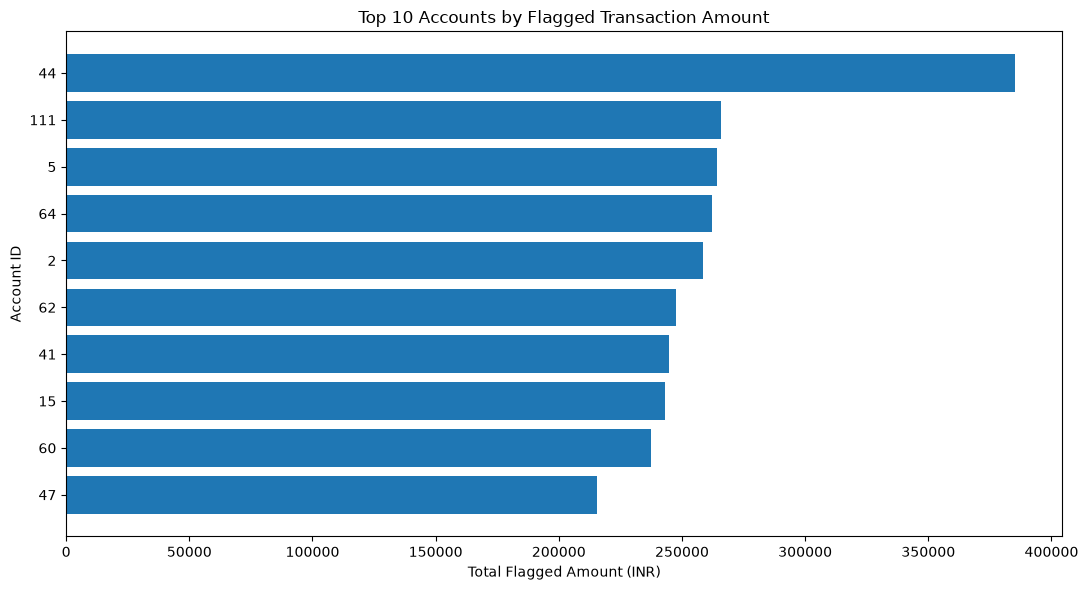

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert aggregation results to DataFrame
account_df = pd.DataFrame(account_results)

# Sort for visualization
account_df = account_df.sort_values(
    "total_flagged_amount",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(11, 6))

plt.barh(
    account_df["account_id"].astype(str),
    account_df["total_flagged_amount"]
)

plt.title("Top 10 Accounts by Flagged Transaction Amount")
plt.xlabel("Total Flagged Amount (INR)")
plt.ylabel("Account ID")

plt.tight_layout()
plt.show()

In [28]:

# BANKLEDGER: FINAL DATABASE VERIFICATION

print("========== MYSQL DATABASE ==========")

mysql_tables = [
    "customers",
    "branches",
    "account_types",
    "accounts",
    "transactions",
    "loans",
    "transaction_flags",
    "balance_audit"
]

mysql_cursor = connection.cursor()

for table in mysql_tables:
    mysql_cursor.execute(f"SELECT COUNT(*) FROM {table}")
    count = mysql_cursor.fetchone()[0]
    print(f"{table}: {count}")

print("\n========== MONGODB DATABASE ==========")

for collection_name in mongo_db.list_collection_names():
    count = mongo_db[collection_name].count_documents({})
    print(f"{collection_name}: {count}")

mysql_cursor.close()


========== MYSQL DATABASE ==========
customers: 100
branches: 5
account_types: 4
accounts: 120
transactions: 650
loans: 60
transaction_flags: 61
balance_audit: 650

========== MONGODB DATABASE ==========
transactions: 650
crud_demo: 0
transaction_flags: 61


True

# 10. Final Results and Project Conclusion

## Project Results

### MySQL Database
- 8 tables successfully created.
- 100 customers.
- 120 accounts.
- 650 transactions.
- 60 loans.
- 61 simulated transaction flags.
- 650 balance audit records.
- Total: 1,650 records across 8 tables.

### MongoDB Atlas
- 650 transaction documents.
- 61 transaction flag documents.
- CRUD operations demonstrated.
- Indexing and performance comparison completed.
- Three aggregation analyses performed.
- Total: 711 business documents.

## Key Learnings

1. Banking data generation using Python.
2. Data handling and analysis using Pandas and NumPy.
3. Relational database design using MySQL.
4. SQL queries, triggers, foreign keys and views.
5. NoSQL database management using MongoDB.
6. CRUD operations, indexing and aggregation pipelines.
7. Database integration and performance analysis.

## Conclusion

The BankLedger project demonstrates how Python, MySQL,
and MongoDB can work together to manage and analyze
simulated banking transaction data.

It provides practical experience in data generation,
database management, data migration, analytical queries,
and simulated suspicious activity monitoring.

The project also demonstrates the importance of database
indexing and combining relational and NoSQL technologies
for different data-management requirements.

**Project Author:** Ketan Balbhadra Sharma

**Project:** BANKLEDGER – Banking Transactions and Suspicious Activity Detection

In [29]:

from pymongo import MongoClient
from urllib.parse import quote_plus
from getpass import getpass

username = "ketansharma1303_db_user"
password = getpass("Enter your new MongoDB password: ")

uri = (
    f"mongodb+srv://{username}:{quote_plus(password)}"
    "@cluster0.ocbuygc.mongodb.net/"
    "?retryWrites=true&w=majority"
)

client = MongoClient(uri, serverSelectionTimeoutMS=10000)

try:
    print(client.admin.command("ping"))
    print("MongoDB Atlas connected successfully!")
except Exception as e:
    print("Connection failed:", e)
finally:
    client.close()


Enter your new MongoDB password:  ········


{'ok': 1}
MongoDB Atlas connected successfully!


In [31]:
from pathlib import Path

project_folder = Path(r"C:\Users\Ketan Sharma\BankLedger_Project")

print("Project folder exists:", project_folder.exists())
print("Folder:", project_folder)

Project folder exists: True
Folder: C:\Users\Ketan Sharma\BankLedger_Project


In [32]:

from pathlib import Path

project_folder = Path(r"C:\Users\Ketan Sharma\BankLedger_Project")
file_path = project_folder / "Database_Design_and_Normalization.md"

documentation = r"""
# BANKLEDGER
## Database Design and Normalization Report

**Project:** Banking Transactions and Suspicious Activity Detection  
**Database:** MySQL - BankLedger  
**Storage Engine:** InnoDB  
**Character Set:** utf8mb4

---

## 1. Database Overview

BankLedger is a relational banking database designed to manage customers,
branches, account types, accounts, transactions, loans, suspicious
transaction flags and account balance audit records.

The database contains eight relational tables.

| Table | Purpose |
|---|---|
| customers | Stores customer information |
| branches | Stores bank branch details |
| account_types | Stores available account categories |
| accounts | Stores customer bank accounts and balances |
| transactions | Stores deposits, withdrawals and transfers |
| loans | Stores customer loan information |
| transaction_flags | Stores suspicious transaction alerts |
| balance_audit | Records account balance changes |

## 2. Functional Dependencies

A functional dependency describes how one attribute or a group of
attributes uniquely determines another attribute or group of attributes.

### 2.1 Customers

Primary key: customer_id  
Additional unique key: email (nullable)

Functional dependencies:

- customer_id -> first_name, last_name, email, phone,
  date_of_birth, address, created_at
- email -> customer_id, first_name, last_name, phone,
  date_of_birth, address, created_at (when email is non-NULL)

### 2.2 Branches

Primary key: branch_id

Functional dependency:

- branch_id -> branch_name, city, state

### 2.3 Account Types

Primary key: account_type_id  
Additional unique key: type_name

Functional dependencies:

- account_type_id -> type_name, description
- type_name -> account_type_id, description

### 2.4 Accounts

Primary key: account_id  
Additional unique key: account_number

Functional dependencies:

- account_id -> customer_id, branch_id, account_type_id,
  account_number, opening_date, balance, status
- account_number -> account_id, customer_id, branch_id,
  account_type_id, opening_date, balance, status

### 2.5 Transactions

Primary key: transaction_id

Functional dependency:

- transaction_id -> account_id, transaction_type, amount,
  transaction_date, description, reference_no, transfer_group_id

### 2.6 Loans

Primary key: loan_id

Functional dependency:

- loan_id -> customer_id, branch_id, loan_type,
  principal_amount, interest_rate, start_date, end_date, loan_status

### 2.7 Transaction Flags

Primary key: flag_id

Functional dependency:

- flag_id -> transaction_id, flag_type, severity,
  flag_reason, flagged_at, status

A transaction can have multiple associated flags because transaction_id
is not declared UNIQUE in this table.

### 2.8 Balance Audit

Primary key: audit_id

Functional dependency:

- audit_id -> account_id, old_balance, new_balance,
  changed_at, change_reason

An account can have multiple audit records.

---

## 3. Normalization

Normalization is the process of organizing relational database tables
to reduce unnecessary duplication and prevent insertion, update and
deletion anomalies.

### 3.1 First Normal Form (1NF)

A table satisfies 1NF when:

- Each column contains individual, atomic values.
- Each row can be uniquely identified.
- There are no repeating groups or multi-valued columns.

Assessment:

The eight BankLedger tables use individual columns for customer details,
account information, transaction values, loan information, flags and
audit records.

The tables use primary keys to identify individual records.

Therefore, the inspected schema is consistent with 1NF, assuming
individual values are stored in each field.

### 3.2 Second Normal Form (2NF)

A table satisfies 2NF when:

- It already satisfies 1NF.
- Every non-key attribute depends on the whole candidate key.
- No partial dependency exists on part of a composite candidate key.

Assessment:

All eight tables have single-column primary keys. Their declared
additional unique candidate keys are also single-column.

Therefore, there can be no partial dependency on a subset of a
composite primary key in these tables.

The inspected schema is consistent with 2NF.

### 3.3 Third Normal Form (3NF)

A table satisfies 3NF when:

- It already satisfies 2NF.
- Non-key attributes do not depend transitively on candidate keys
  through other non-key attributes.

Assessment:

BankLedger separates customers, branches, account types and accounts
into different tables.

For example:

- Customer details are stored in customers.
- Branch details are stored in branches.
- Account category details are stored in account_types.
- Accounts reference these entities using foreign keys.

This avoids repeatedly storing customer, branch and account-type
descriptions in every related account or transaction record.

Based on the declared keys and intended business meanings, the
inspected schema is consistent with 3NF.

Note: This is a schema-level assessment. Full proof of 3NF also depends
on all business-rule functional dependencies, not only declared keys.

---

## 4. Primary Keys and Unique Constraints

| Table | Primary Key | Additional Unique Key |
|---|---|---|
| customers | customer_id | email |
| branches | branch_id | None |
| account_types | account_type_id | type_name |
| accounts | account_id | account_number |
| transactions | transaction_id | None |
| loans | loan_id | None |
| transaction_flags | flag_id | None |
| balance_audit | audit_id | None |

Note: The customers.email column is nullable. MySQL permits multiple
NULL values in a UNIQUE column.

## 5. Foreign Key Relationships

| Child Table | Foreign Key | Parent Table |
|---|---|---|
| accounts | customer_id | customers |
| accounts | branch_id | branches |
| accounts | account_type_id | account_types |
| transactions | account_id | accounts |
| loans | customer_id | customers |
| loans | branch_id | branches |
| transaction_flags | transaction_id | transactions |
| balance_audit | account_id | accounts |

These relationships maintain referential integrity between related
banking records.

## 6. Check Constraints

| Table | Constraint | Rule |
|---|---|---|
| accounts | accounts_chk_1 | balance >= 0 |
| transactions | transactions_chk_1 | amount > 0 |
| loans | loans_chk_1 | principal_amount > 0 |
| loans | loans_chk_2 | interest_rate >= 0 |

These constraints prevent invalid balance, transaction and loan values.

## 7. Transaction Types

The transactions table supports four transaction types:

- DEPOSIT
- WITHDRAWAL
- TRANSFER_IN
- TRANSFER_OUT

The transfer_group_id column is available to associate related
transfer records.

## 8. Database Integrity

The database uses:

- Primary keys for unique record identification.
- Unique constraints to prevent duplicate candidate-key values.
- Foreign keys to maintain relationships.
- Check constraints to restrict invalid numeric values.
- Database triggers for transaction balance updates and audit logging.

## 9. Conclusion

The BankLedger database separates major banking entities into eight
related tables. Its primary keys, unique constraints, foreign keys
and check constraints support data integrity.

The schema-level assessment indicates consistency with 1NF, 2NF
and 3NF under the stated business assumptions.

This database design provides a structured foundation for banking
transaction analysis, suspicious activity monitoring and reporting.
"""

if not project_folder.exists():
    print("ERROR: Project folder was not found.")
elif file_path.exists():
    print("The documentation file already exists.")
    print("No existing file was overwritten.")
    print("File:", file_path)
else:
    file_path.write_text(documentation.strip(), encoding="utf-8")
    print("SUCCESS: Documentation created!")
    print("File:", file_path)
    print("File size:", file_path.stat().st_size, "bytes")


SUCCESS: Documentation created!
File: C:\Users\Ketan Sharma\BankLedger_Project\Database_Design_and_Normalization.md
File size: 7650 bytes


In [33]:
from pymongo import MongoClient
from pprint import pprint

# Use your existing connected MongoDB client
db = client["BankLedger"]

print("TRANSACTION DOCUMENT:")
pprint(db.transactions.find_one())

print("\nAVAILABLE FIELDS:")
print(list(db.transactions.find_one().keys()))

print("\nTRANSACTION DESCRIPTIONS:")
for doc in db.transactions.find().limit(10):
    print(doc.get("description"))

TRANSACTION DOCUMENT:


InvalidOperation: Cannot use MongoClient after close

In [1]:
from getpass import getpass

password = getpass("Enter your MongoDB password: ")

Enter your MongoDB password:  ········


In [3]:
from pymongo import MongoClient
from urllib.parse import quote_plus
from getpass import getpass
from pprint import pprint

username = "ketansharma1303_db_user"
password = getpass("Enter your MongoDB password: ")

uri = (
    f"mongodb+srv://{username}:{quote_plus(password)}"
    "@cluster0.ocbuygc.mongodb.net/"
    "?retryWrites=true&w=majority"
)

# Create a NEW connection
mongo_client = MongoClient(
    uri,
    serverSelectionTimeoutMS=10000
)

# Verify connection
print(mongo_client.admin.command("ping"))

# Connect to database
db = mongo_client["BankLedger"]

print("\nTRANSACTION DOCUMENT:")
sample = db.transactions.find_one()
pprint(sample)

if sample:
    print("\nAVAILABLE FIELDS:")
    print(list(sample.keys()))

    print("\nTRANSACTION DESCRIPTIONS:")
    for doc in db.transactions.find().limit(10):
        print(doc.get("description"))
else:
    print("No transaction documents found.")

Enter your MongoDB password:  ········


{'ok': 1}

TRANSACTION DOCUMENT:
{'_id': ObjectId('6af861167876819ddb3aa473'),
 'account_id': 1,
 'amount': 15351.28,
 'transaction_date': datetime.datetime(2025, 11, 14, 16, 4, 49),
 'transaction_day': '2025-11-14',
 'transaction_hour': 16,
 'transaction_id': 236,
 'transaction_type': 'WITHDRAWAL'}

AVAILABLE FIELDS:
['_id', 'transaction_id', 'account_id', 'transaction_type', 'amount', 'transaction_date', 'transaction_day', 'transaction_hour']

TRANSACTION DESCRIPTIONS:
None
None
None
None
None
None
None
None
None
None


In [4]:
pipeline = [
    {
        "$group": {
            "_id": "$transaction_type",
            "transaction_count": {"$sum": 1},
            "total_amount": {"$sum": "$amount"},
            "average_amount": {"$avg": "$amount"},
            "maximum_amount": {"$max": "$amount"}
        }
    },
    {
        "$sort": {"total_amount": -1}
    }
]

results = list(db.transactions.aggregate(pipeline))

print("========== CASH FLOW ANALYSIS ==========")

for row in results:
    print(f"\nTransaction type: {row['_id']}")
    print(f"Count: {row['transaction_count']}")
    print(f"Total: ₹{row['total_amount']:,.2f}")
    print(f"Average: ₹{row['average_amount']:,.2f}")
    print(f"Maximum: ₹{row['maximum_amount']:,.2f}")

========== CASH FLOW ANALYSIS ==========

Transaction type: DEPOSIT
Count: 408
Total: ₹11,739,894.33
Average: ₹28,774.25
Maximum: ₹149,454.81

Transaction type: WITHDRAWAL
Count: 242
Total: ₹2,958,037.89
Average: ₹12,223.30
Maximum: ₹24,993.08


In [8]:
import mysql.connector
from getpass import getpass

mysql_password = getpass("Enter your MySQL password: ")

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password=mysql_password,
    database="BankLedger"
)

if connection.is_connected():
    print("MySQL connected successfully!")

Enter your MySQL password:  ········


MySQL connected successfully!


In [9]:
import pandas as pd

migration_df = pd.read_sql(
    """
    SELECT
        transaction_id,
        account_id,
        transaction_type,
        amount,
        transaction_date,
        description
    FROM transactions
    ORDER BY transaction_id
    """,
    connection
)

print("MYSQL RECORDS:", len(migration_df))
print("MONGODB RECORDS:", db.transactions.count_documents({}))

print("\nTRANSACTION TYPES:")
print(migration_df["transaction_type"].value_counts())

print("\nDESCRIPTION SUMMARY:")
print(migration_df["description"].value_counts(dropna=False))

MYSQL RECORDS: 652
MONGODB RECORDS: 650

TRANSACTION TYPES:
transaction_type
DEPOSIT         408
WITHDRAWAL      242
TRANSFER_OUT      1
TRANSFER_IN       1
Name: count, dtype: int64

DESCRIPTION SUMMARY:
description
Deposit transaction         347
Withdrawal transaction      242
High-value deposit           61
Fund transfer - sender        1
Fund transfer - receiver      1
Name: count, dtype: int64


C:\Users\Ketan Sharma\AppData\Local\Temp\ipykernel_20972\1130378223.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  migration_df = pd.read_sql(


In [10]:
backup_name = "transactions_backup_20261115"

if backup_name in db.list_collection_names():
    print("Backup already exists. No changes made.")
else:
    existing_docs = list(db.transactions.find({}))

    if existing_docs:
        db[backup_name].insert_many(existing_docs)

    print("Backup created successfully!")
    print("Backup records:", db[backup_name].count_documents({}))

Backup created successfully!
Backup records: 650


In [11]:
from pymongo import ASCENDING, DESCENDING

# Convert MySQL records into MongoDB documents
mongo_records = migration_df.copy()

mongo_records["transaction_date"] = pd.to_datetime(
    mongo_records["transaction_date"]
)

mongo_records["transaction_date"] = (
    mongo_records["transaction_date"].dt.to_pydatetime()
)

mongo_records = mongo_records.astype(object).where(
    pd.notna(mongo_records), None
)

documents = mongo_records.to_dict("records")

# Replace MongoDB transactions collection
db.transactions.drop()

if documents:
    db.transactions.insert_many(documents)

# Recreate indexes
db.transactions.create_index(
    [("transaction_id", ASCENDING)],
    unique=True
)

db.transactions.create_index(
    [("account_id", ASCENDING)]
)

db.transactions.create_index(
    [("account_id", ASCENDING),
     ("transaction_date", DESCENDING)]
)

print("========== MIGRATION RESULT ==========")
print("MySQL records:", len(migration_df))
print("MongoDB records:", db.transactions.count_documents({}))
print("Unique transaction IDs:",
      db.transactions.distinct("transaction_id").__len__())
print("Backup records:", db[backup_name].count_documents({}))
print("Migration completed!")

========== MIGRATION RESULT ==========
MySQL records: 652
MongoDB records: 652
Unique transaction IDs: 652
Backup records: 650
Migration completed!


In [12]:
pipeline = [
    {
        "$group": {
            "_id": {
                "description": "$description",
                "type": "$transaction_type"
            },
            "transaction_count": {"$sum": 1},
            "total_amount": {"$sum": "$amount"},
            "average_amount": {"$avg": "$amount"},
            "maximum_amount": {"$max": "$amount"}
        }
    },
    {"$sort": {"total_amount": -1}}
]

results = list(db.transactions.aggregate(pipeline))

print("========== MONGODB TRANSACTION CATEGORY ANALYSIS ==========")

for row in results:
    print("\nCategory:", row["_id"]["description"])
    print("Type:", row["_id"]["type"])
    print("Count:", row["transaction_count"])
    print("Total: ₹{:,.2f}".format(row["total_amount"]))
    print("Average: ₹{:,.2f}".format(row["average_amount"]))
    print("Maximum: ₹{:,.2f}".format(row["maximum_amount"]))

========== MONGODB TRANSACTION CATEGORY ANALYSIS ==========

Category: High-value deposit
Type: DEPOSIT
Count: 61
Total: ₹7,128,100.12
Average: ₹116,854.10
Maximum: ₹149,454.81

Category: Deposit transaction
Type: DEPOSIT
Count: 347
Total: ₹4,611,794.21
Average: ₹13,290.47
Maximum: ₹24,910.23

Category: Withdrawal transaction
Type: WITHDRAWAL
Count: 242
Total: ₹2,958,037.89
Average: ₹12,223.30
Maximum: ₹24,993.08

Category: Fund transfer - receiver
Type: TRANSFER_IN
Count: 1
Total: ₹100.00
Average: ₹100.00
Maximum: ₹100.00

Category: Fund transfer - sender
Type: TRANSFER_OUT
Count: 1
Total: ₹100.00
Average: ₹100.00
Maximum: ₹100.00


In [13]:
print("========== TRANSACTION FLAGS ==========")

print("Total flags:", db.transaction_flags.count_documents({}))

for document in db.transaction_flags.find().limit(3):
    print("\n", document)

print("\n========== COLLECTION FIELDS ==========")

sample = db.transaction_flags.find_one()

if sample:
    print(list(sample.keys()))

========== TRANSACTION FLAGS ==========
Total flags: 61

 {'_id': ObjectId('6af861737876819ddb3aa6fd'), 'flag_id': 1, 'transaction_id': 1, 'flag_type': 'HIGH_VALUE_TRANSACTION', 'severity': 'HIGH', 'flag_reason': 'Deposit exceeds the project high-value monitoring threshold of INR 80000', 'flagged_at': datetime.datetime(2026, 11, 14, 16, 47, 13), 'status': 'OPEN'}

 {'_id': ObjectId('6af861737876819ddb3aa6fe'), 'flag_id': 2, 'transaction_id': 2, 'flag_type': 'HIGH_VALUE_TRANSACTION', 'severity': 'HIGH', 'flag_reason': 'Deposit exceeds the project high-value monitoring threshold of INR 80000', 'flagged_at': datetime.datetime(2026, 11, 14, 16, 47, 13), 'status': 'OPEN'}

 {'_id': ObjectId('6af861737876819ddb3aa6ff'), 'flag_id': 3, 'transaction_id': 3, 'flag_type': 'HIGH_VALUE_TRANSACTION', 'severity': 'HIGH', 'flag_reason': 'Deposit exceeds the project high-value monitoring threshold of INR 80000', 'flagged_at': datetime.datetime(2026, 11, 14, 16, 47, 13), 'status': 'OPEN'}

========== CO

In [14]:
pipeline = [
    {
        "$lookup": {
            "from": "transactions",
            "localField": "transaction_id",
            "foreignField": "transaction_id",
            "as": "transaction"
        }
    },
    {"$unwind": "$transaction"},
    {
        "$group": {
            "_id": "$transaction.account_id",
            "flagged_transactions": {"$sum": 1},
            "total_flagged_amount": {
                "$sum": "$transaction.amount"
            },
            "maximum_flagged_amount": {
                "$max": "$transaction.amount"
            },
            "high_severity_count": {
                "$sum": {
                    "$cond": [
                        {"$eq": ["$severity", "HIGH"]},
                        1,
                        0
                    ]
                }
            },
            "open_alerts": {
                "$sum": {
                    "$cond": [
                        {"$eq": ["$status", "OPEN"]},
                        1,
                        0
                    ]
                }
            }
        }
    },
    {"$sort": {"total_flagged_amount": -1}}
]

results = list(db.transaction_flags.aggregate(pipeline))

print("========== FLAGGED ACCOUNT ANALYSIS ==========")
print("Accounts with flags:", len(results))

for row in results:
    print("\nAccount ID:", row["_id"])
    print("Flagged transactions:", row["flagged_transactions"])
    print("Total flagged amount: ₹{:,.2f}".format(
        row["total_flagged_amount"]
    ))
    print("Maximum flagged amount: ₹{:,.2f}".format(
        row["maximum_flagged_amount"]
    ))
    print("High severity alerts:", row["high_severity_count"])
    print("Open alerts:", row["open_alerts"])

========== FLAGGED ACCOUNT ANALYSIS ==========
Accounts with flags: 49

Account ID: 44
Flagged transactions: 3
Total flagged amount: ₹385,056.33
Maximum flagged amount: ₹145,764.93
High severity alerts: 3
Open alerts: 3

Account ID: 111
Flagged transactions: 2
Total flagged amount: ₹265,840.08
Maximum flagged amount: ₹138,011.63
High severity alerts: 2
Open alerts: 2

Account ID: 5
Flagged transactions: 2
Total flagged amount: ₹264,130.46
Maximum flagged amount: ₹144,841.06
High severity alerts: 2
Open alerts: 2

Account ID: 64
Flagged transactions: 2
Total flagged amount: ₹262,128.21
Maximum flagged amount: ₹149,454.81
High severity alerts: 2
Open alerts: 2

Account ID: 2
Flagged transactions: 2
Total flagged amount: ₹258,436.22
Maximum flagged amount: ₹130,539.91
High severity alerts: 2
Open alerts: 2

Account ID: 62
Flagged transactions: 2
Total flagged amount: ₹247,639.24
Maximum flagged amount: ₹144,866.12
High severity alerts: 2
Open alerts: 2

Account ID: 41
Flagged transactions


# MySQL vs MongoDB: Comparative Analysis

## 1. Overview

BankLedger uses MySQL as its primary relational database and MongoDB as its document-oriented database for transaction analytics.

## 2. Database Comparison

| Feature | MySQL | MongoDB |
|---|---|---|
| Database type | Relational (RDBMS) | NoSQL document database |
| Data structure | Tables and rows | Collections and documents |
| Schema | Structured schema | Flexible document structure |
| Relationships | Primary and foreign keys | Embedded documents and references |
| Transactions | ACID transactions | Supports multi-document transactions |
| Constraints | Foreign keys, CHECK, UNIQUE | Document validation and indexes |
| Query language | SQL | MongoDB Query Language |
| Main project purpose | Banking records and balance management | Transaction analytics and aggregation |

## 3. Implementation Results

### MySQL
- 8 relational tables.
- 100 customers.
- 120 accounts.
- 652 transactions.
- 60 loans.
- 61 transaction flags.
- 652 balance audit records.
- Stored procedures and triggers for transaction processing.
- Foreign keys and CHECK constraints.

### MongoDB
- 652 transaction documents.
- 61 transaction flag documents.
- Unique transaction ID index.
- Account ID index.
- Compound account ID and transaction date index.
- Aggregation pipelines for transaction classification and flagged-account analysis.

## 4. MongoDB Index Performance Test

A query for account ID 1 was tested:

| Metric | Without index | With index |
|---|---:|---:|
| Query execution plan | COLLSCAN | IXSCAN |
| Documents examined | 650 | 8 |
| Documents returned | 8 | 8 |

Reduction in documents examined: approximately 98.77%.

Note: This is a small demonstration dataset. Execution time differences are not sufficient to establish production-level performance improvements.

## 5. Analytical Findings

- 408 deposits and 242 withdrawals were present in the original 650-document dataset.
- After migration, MongoDB contains 652 transactions, including two fund-transfer records.
- High-value deposit monitoring identified 61 alerts.
- MongoDB aggregation identified 49 accounts associated with these alerts.
- Account 44 had the highest aggregate flagged transaction value of ₹385,056.33.

## 6. Conclusion

MySQL is suitable for maintaining structured banking records, enforcing relationships, managing account balances and processing transactions.

MongoDB provides flexible document storage, indexing and aggregation capabilities for transaction analysis and monitoring.

Using both databases demonstrates how relational and NoSQL technologies can complement one another in a banking analytics application.


In [1]:
import mysql.connector
from getpass import getpass

mysql_password = getpass("Enter MySQL password: ")

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password=mysql_password,
    database="BankLedger"
)

Enter MySQL password:  ········


In [2]:
print("MySQL Connection Status:", connection.is_connected())
print("Connected Database: BankLedger")

MySQL Connection Status: True
Connected Database: BankLedger
